In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('Daily_Stock_Prices_Dataset.csv')
df.head()

,Date,AAPL,MSFT,TSLA,gold,SPY
0,2020-01-02,72.716087,153.323257,28.684000,1524.500000,301.194916
1,2020-01-03,72.009132,151.414154,29.534000,1549.199951,298.914215
2,2020-01-06,72.582924,151.805481,30.102667,1566.199951,300.054565
3,2020-01-07,72.241524,150.421356,31.270666,1571.800049,299.210907
4,2020-01-08,73.403656,152.817352,32.809334,1557.400024,300.805572


In [9]:
df.dtypes
df.isnull().sum()

Date    0
AAPL    0
MSFT    0
TSLA    0
gold    0
SPY     0
dtype: int64

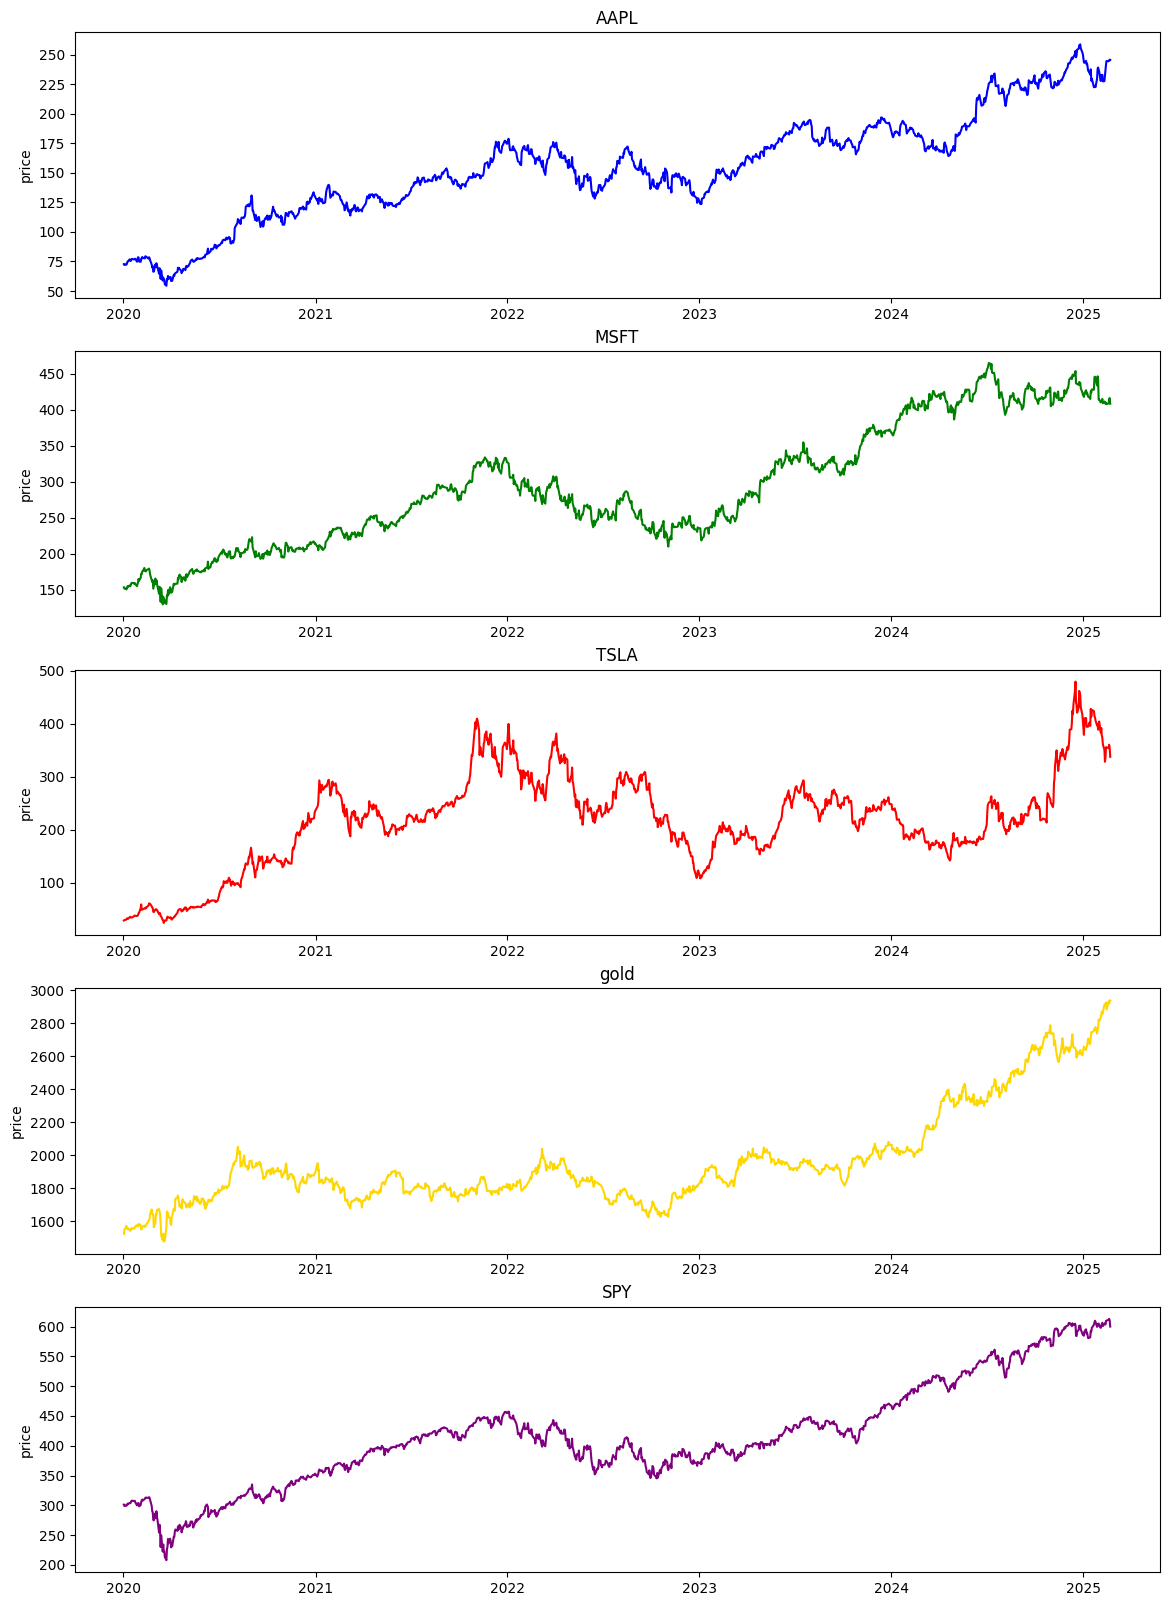

In [17]:
fig, axes = plt.subplots(5, 1, figsize=(14, 20))

assets = ['AAPL', 'MSFT', 'TSLA', 'gold', 'SPY']
colors = ['blue', 'green', 'red', 'gold', 'purple']

for ax, asset, color in zip(axes, assets, colors):
    ax.plot(df['Date'], df[asset], color=color)
    ax.set_title(f'{asset}')
    ax.set_ylabel('price')

plt.show()

In [18]:
df['Date'] = pd.to_datetime(df['Date'])
print('Первая дата ', df['Date'].min())
print('Последняя дата ', df['Date'].max())
print('Всего дней ', len(df))

Первая дата  2020-01-02 00:00:00
Последняя дата  2025-02-21 00:00:00
Всего дней  1292


In [21]:
df_returns = df.copy()
for asset in assets:
    df_returns[asset] = df[asset].pct_change() * 100

df_returns = df_returns.dropna()

print('Размер таблицы доходностей', df_returns.shape)
print('Статистика ')
df_returns[assets].describe()

Размер таблицы доходностей (1291, 6)
Статистика 


,AAPL,MSFT,TSLA,gold,SPY
count,1291.000000,1291.000000,1291.000000,1291.000000,1291.000000
mean,0.114080,0.094226,0.279616,0.056040,0.062030
std,1.990275,1.915132,4.215355,1.021441,1.311619
min,-12.864710,-14.739043,-21.062824,-4.978726,-10.942397
25%,-0.842313,-0.814426,-2.013670,-0.439161,-0.510364
50%,0.118665,0.110931,0.166255,0.074194,0.091159
75%,1.198876,1.083981,2.341148,0.627603,0.727403
max,11.980836,14.216890,21.919035,5.947668,9.060315


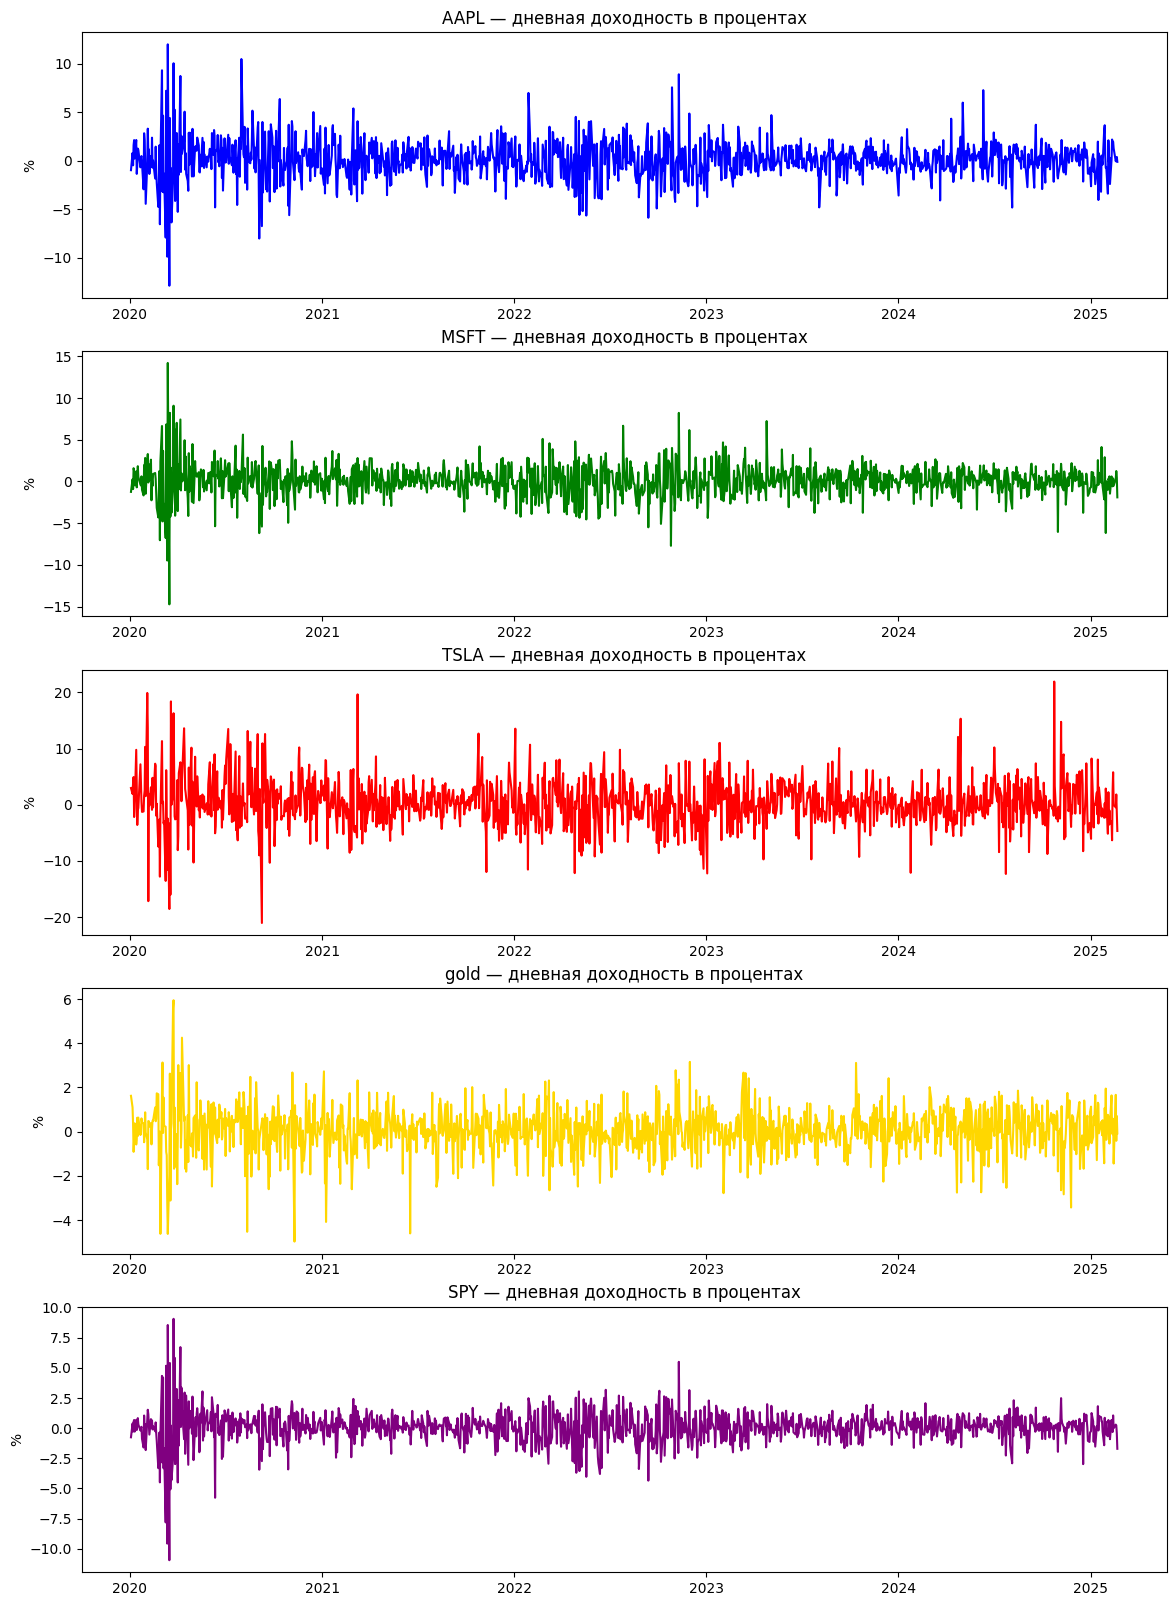

In [27]:
fig, axes = plt.subplots(5, 1, figsize=(14, 20))

for ax, asset, color in zip(axes, assets, colors):
    ax.plot(df_returns['Date'], df_returns[asset], color=color)
    ax.set_title(f'{asset} — дневная доходность в процентах')
    ax.set_ylabel('%')

plt.show()

In [29]:
df_returns[assets].describe()

# у TSLA большая волатильность, придется нормализировать данные

,AAPL,MSFT,TSLA,gold,SPY
count,1291.000000,1291.000000,1291.000000,1291.000000,1291.000000
mean,0.114080,0.094226,0.279616,0.056040,0.062030
std,1.990275,1.915132,4.215355,1.021441,1.311619
min,-12.864710,-14.739043,-21.062824,-4.978726,-10.942397
25%,-0.842313,-0.814426,-2.013670,-0.439161,-0.510364
50%,0.118665,0.110931,0.166255,0.074194,0.091159
75%,1.198876,1.083981,2.341148,0.627603,0.727403
max,11.980836,14.216890,21.919035,5.947668,9.060315


In [30]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import tensorflow as tf

In [31]:
WINDOW_SIZE = 30
TEST_RATIO = 0.2

In [32]:
split_idx = int(len(df_returns) * (1 - TEST_RATIO))

df_train = df_returns.iloc[:split_idx].copy()
df_test = df_returns.iloc[split_idx:].copy()

In [33]:
scaler = StandardScaler()

scaler.fit(df_train[assets])

train_scaled = scaler.transform(df_train[assets])
test_scaled = scaler.transform(df_test[assets])

print('Train после нормализации — среднее:', train_scaled.mean(axis=0).round(3))
print('Train после нормализации — std:', train_scaled.std(axis=0).round(3))

Train после нормализации — среднее: [ 0. -0.  0. -0.  0.]
Train после нормализации — std: [1. 1. 1. 1. 1.]


In [ ]:
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i : i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, WINDOW_SIZE)
X_test, y_test = create_sequences(test_scaled, WINDOW_SIZE)

X_train shape: (1002, 30, 5)
y_train shape: (1002, 5)
X_test shape: (229, 30, 5)
y_test shape: (229, 5)
